# 02 Pipeline: the judge and the IP in one step

**Question.** What does the judge propose in one step, what does the integer program adopt or
reject, and does each outcome (a) to (e) come out of the IP as designed?

Pipeline: new prompt + current forest -> judge (scores and proposals) -> integer program (Gurobi)
-> new forest + action. The judge never decides. The `OracleJudge` derives every score from the ideal
forest (no API calls); the `LLMJudge` asks a model (not chosen yet, see `config.yaml`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from forest import viz
from forest.ip import ACTIONS, Params, load_config
from forest.model import load_ideal

cfg = load_config(ROOT / "config.yaml")
P = Params.from_config(cfg)
ideal = load_ideal()
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)

import json
import subprocess

from forest.ip import solve
from forest.judge import LLMJudge, OracleJudge
from forest.simulate import run

oracle = OracleJudge(ideal, cfg["oracle"]["noise"], cfg["seed"])

## A walkthrough step with the oracle judge
The IP is run over the arrival order with the oracle; the walkthrough step is the first step in
which the IP restructures (e).

step 17, prompt p22: 'What does it mean geometrically that a vector is an eigenvector?' (intended a)


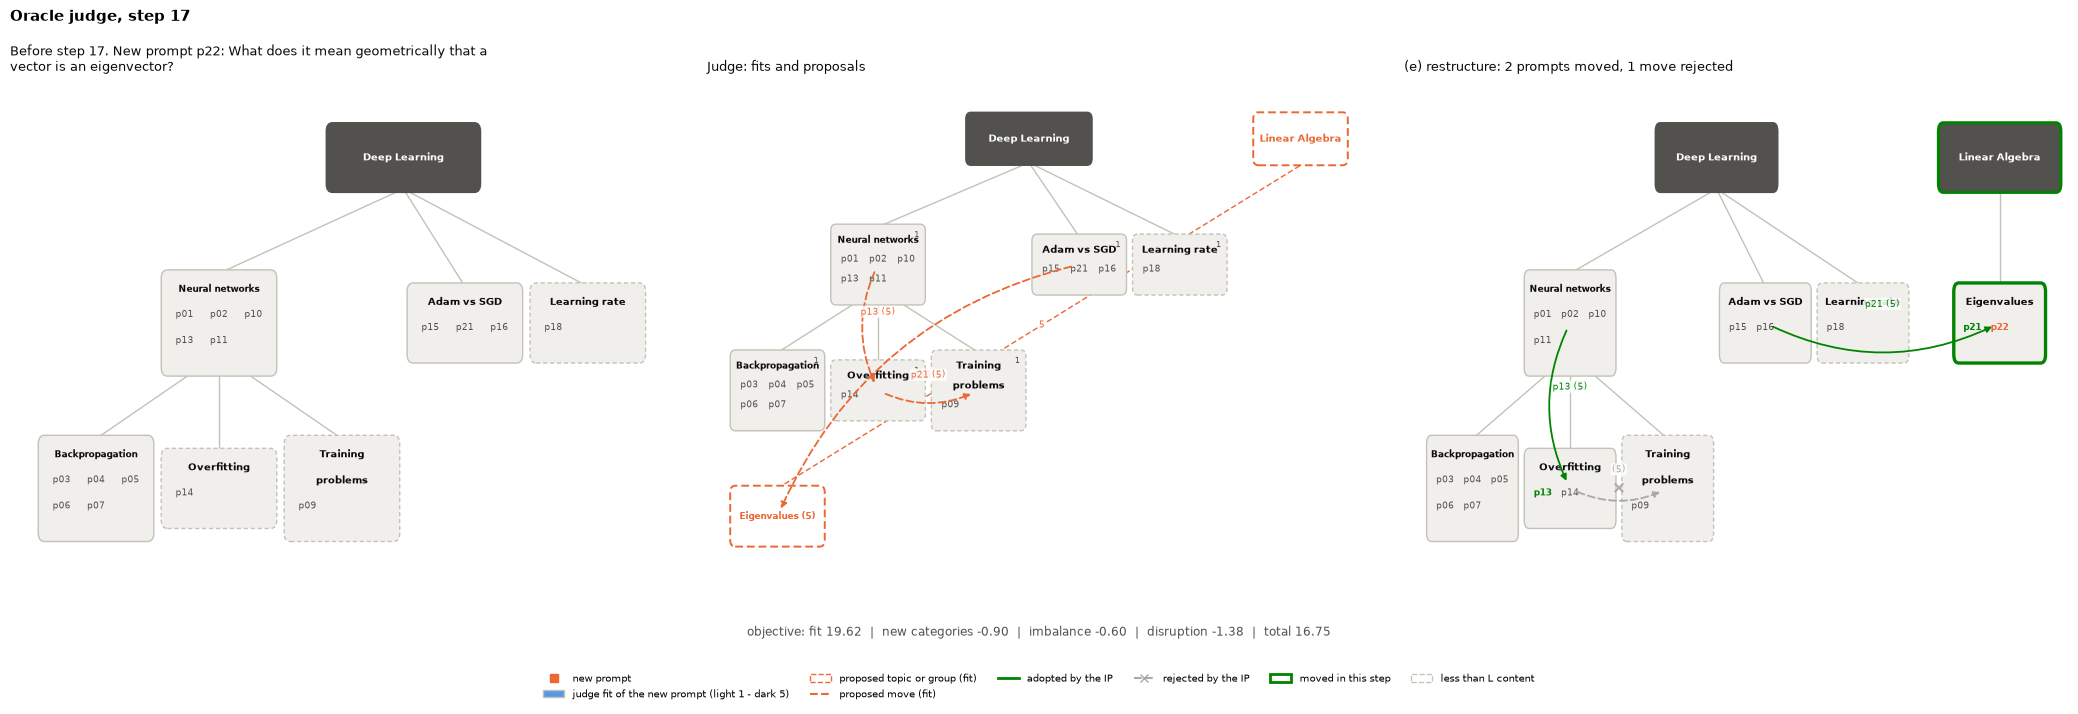

In [2]:
r = run("ip", ideal, oracle, P, save=False)
s = next((s for s in r.steps if s.decision.action == "e"), r.steps[-1])
print(f"step {s.step}, prompt {s.prompt.id}: {s.prompt.text!r} (intended {s.intended})")
fig = viz.step_view(s.before, s.judge, s.decision, s.after, P, title=f"Oracle judge, step {s.step}")
fig.savefig(FIG / "02_walkthrough_oracle.png", dpi=130, bbox_inches="tight")
plt.show()

The raw judge output for this step:

In [3]:
print(s.judge.model_dump_json(indent=1))

{
 "existing": [
  {
   "topic_id": "t01a",
   "fit": 1
  },
  {
   "topic_id": "t02a",
   "fit": 1
  },
  {
   "topic_id": "t07b",
   "fit": 1
  },
  {
   "topic_id": "t12b",
   "fit": 1
  },
  {
   "topic_id": "t13a",
   "fit": 1
  },
  {
   "topic_id": "t15b",
   "fit": 1
  }
 ],
 "proposed": [
  {
   "name": "Eigenvalues",
   "fit": 5,
   "parents": [
    {
     "parent": "NEW_GROUP:Linear Algebra",
     "fit": 5
    }
   ]
  }
 ],
 "restructure": [
  {
   "kind": "topic",
   "id": "t12b",
   "to": "t13a",
   "fit": 5
  },
  {
   "kind": "prompt",
   "id": "p13",
   "to": "t12b",
   "fit": 5
  },
  {
   "kind": "prompt",
   "id": "p21",
   "to": "Eigenvalues",
   "fit": 5
  }
 ]
}


In [4]:
d = s.decision
print(f"model size: {d.size} (pip license limit 2000 each); solve time {1000 * d.solve_s:.1f} ms")
print(f"action: ({d.action}) {ACTIONS[d.action]}")
print("proposed topics adopted:", d.adopted, "| rejected:", d.rejected)
for m, ok in d.moves:
    print(f"  move {m.kind} {m.id} -> {m.to} (fit {m.fit}): {'adopted' if ok else 'rejected' if ok is False else 'unusable'}")
print("changes:", {k: v for k, v in d.diff.items() if v})
print("objective terms:", {k: round(v, 3) for k, v in d.terms.items()})

model size: {'vars': 94, 'constrs': 147} (pip license limit 2000 each); solve time 1.3 ms
action: (e) restructure
proposed topics adopted: ['Eigenvalues'] | rejected: []
  move topic t12b -> t13a (fit 5): rejected
  move prompt p13 -> t12b (fit 5): adopted
  move prompt p21 -> Eigenvalues (fit 5): adopted
changes: {'moved_prompts': ['p13', 'p21']}
objective terms: {'fit': 19.625, 'new categories': -0.9, 'imbalance': -0.6, 'disruption': -1.38, 'total': 16.745}


## The same step with the LLM judge
The LLM judge sees the same forest and prompt. It runs only once a model is chosen (`llm.model` in
`config.yaml`, key in `.env`); answers are cached, so a re-run costs nothing.

In [5]:
llm = LLMJudge(cfg)
if llm.available:
    out = llm(s.before, s.prompt, s.step)
    after, dec = solve(s.before, s.prompt, out, s.step, P)
    fig = viz.step_view(s.before, out, dec, after, P, title=f"LLM judge ({llm.model}), step {s.step}")
    fig.savefig(FIG / "02_walkthrough_llm.png", dpi=130, bbox_inches="tight")
    plt.show()
    print(out.model_dump_json(indent=1))
    print(f"model size {dec.size}, solve {1000 * dec.solve_s:.1f} ms, action ({dec.action}), adopted {dec.adopted}")
else:
    print("skipped: no LLM model chosen yet (config.yaml llm.model, key LLM_API_KEY in .env)")

skipped: no LLM model chosen yet (config.yaml llm.model, key LLM_API_KEY in .env)


## One step view per unit-test case
The cases of `tests/test_ip.py`: tiny hand-built forests with hand-set judge outputs, one per
outcome. Each figure is saved to `outputs/figures/02_case_*.png`.

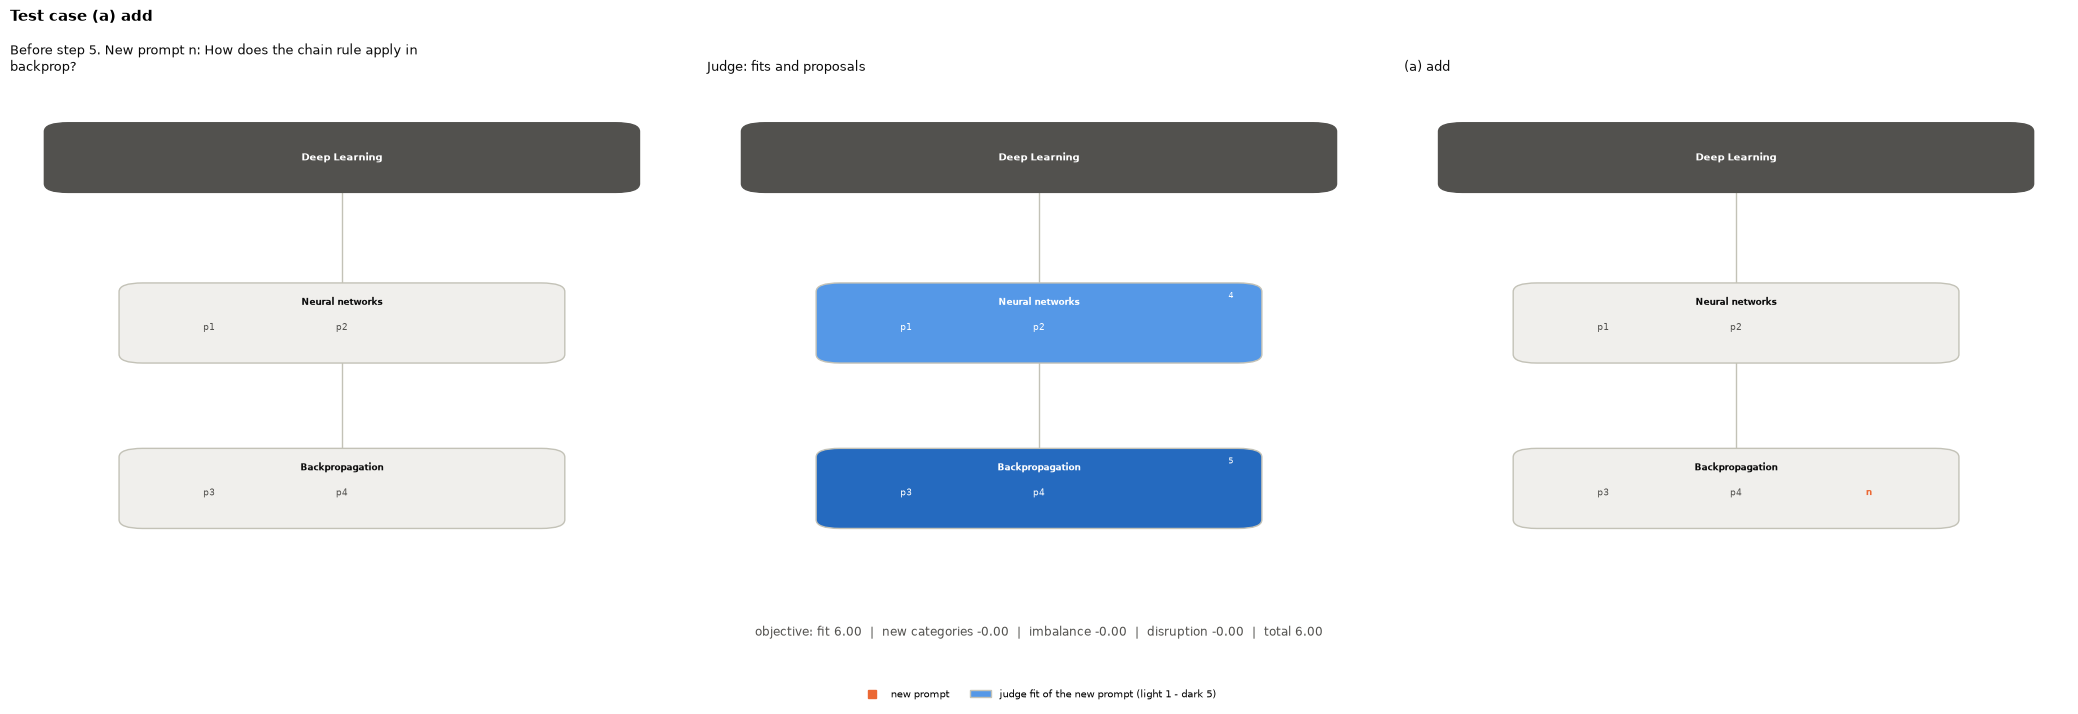

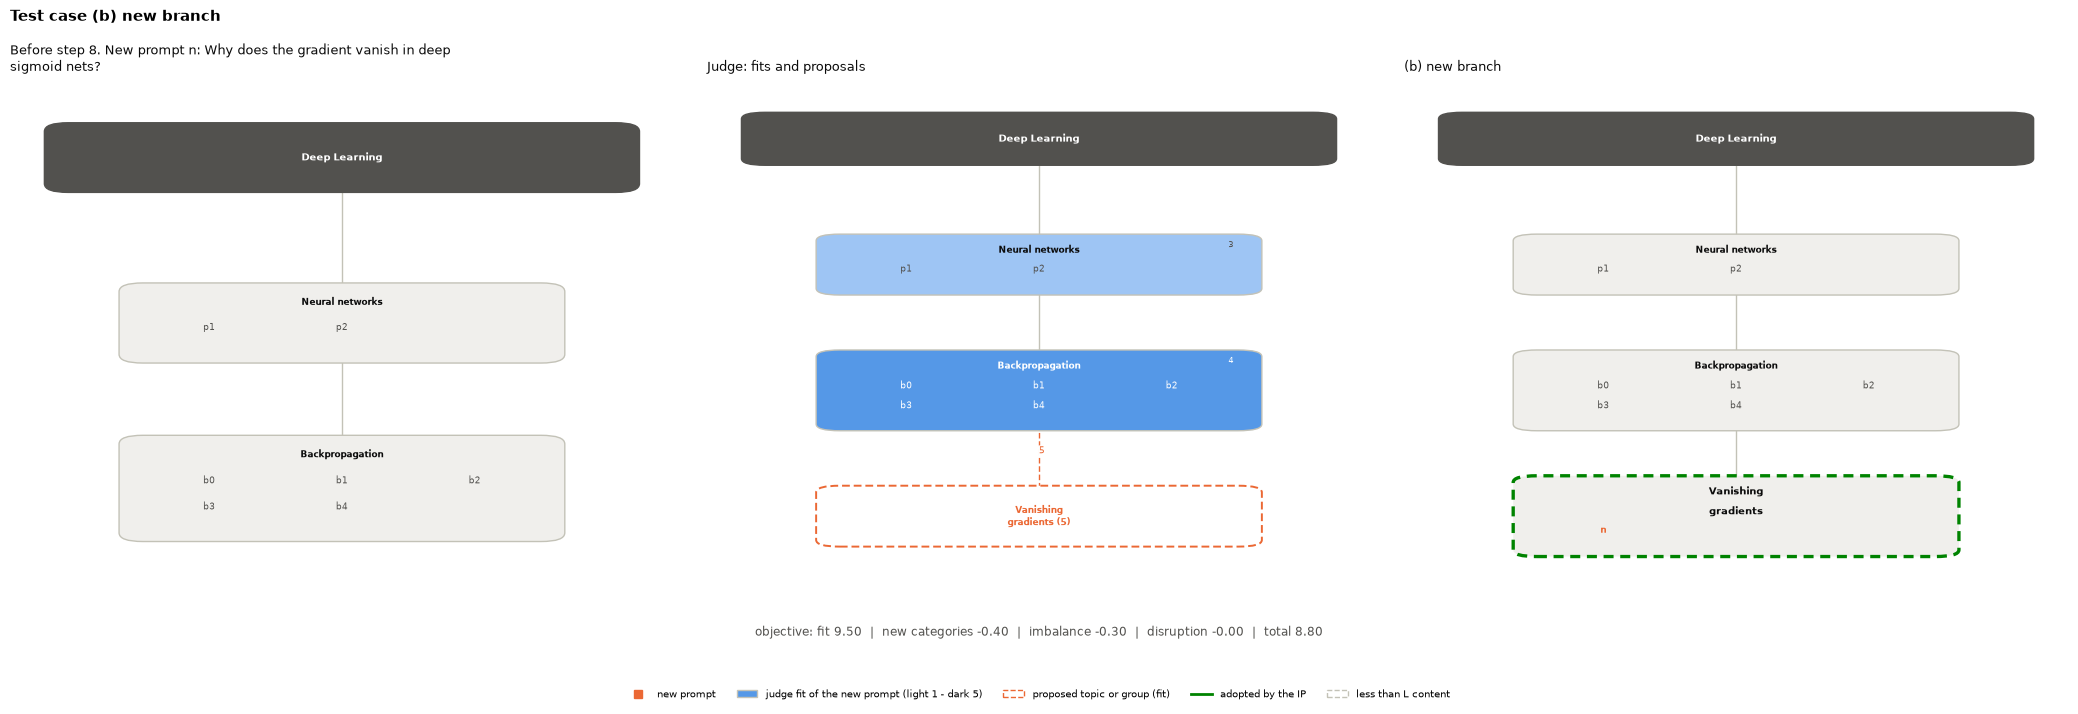

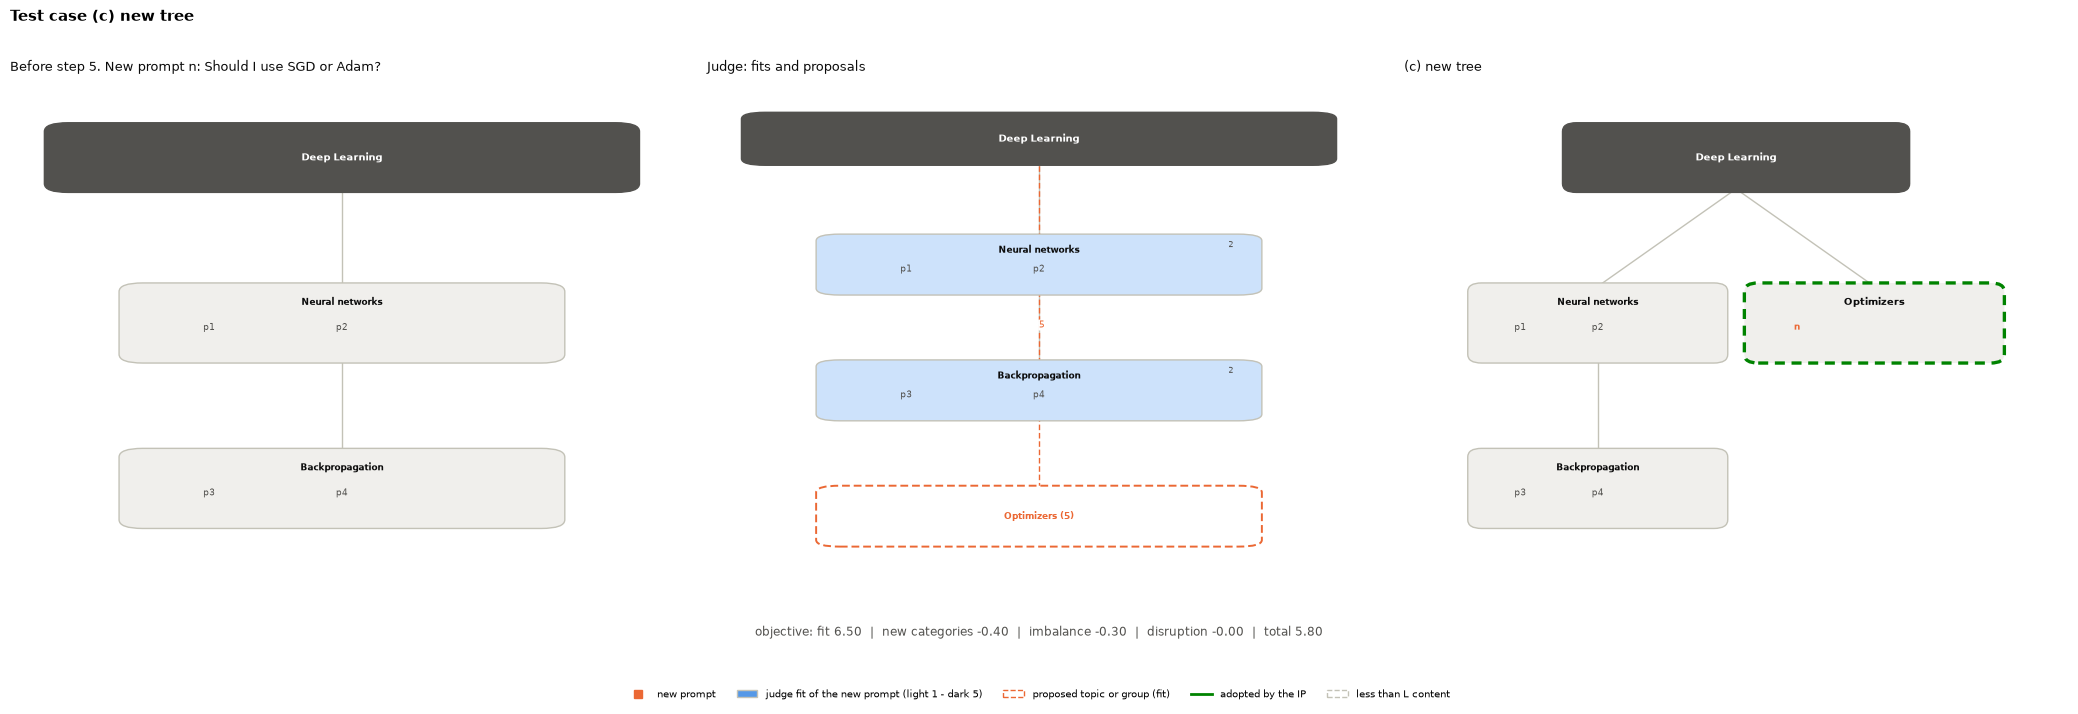

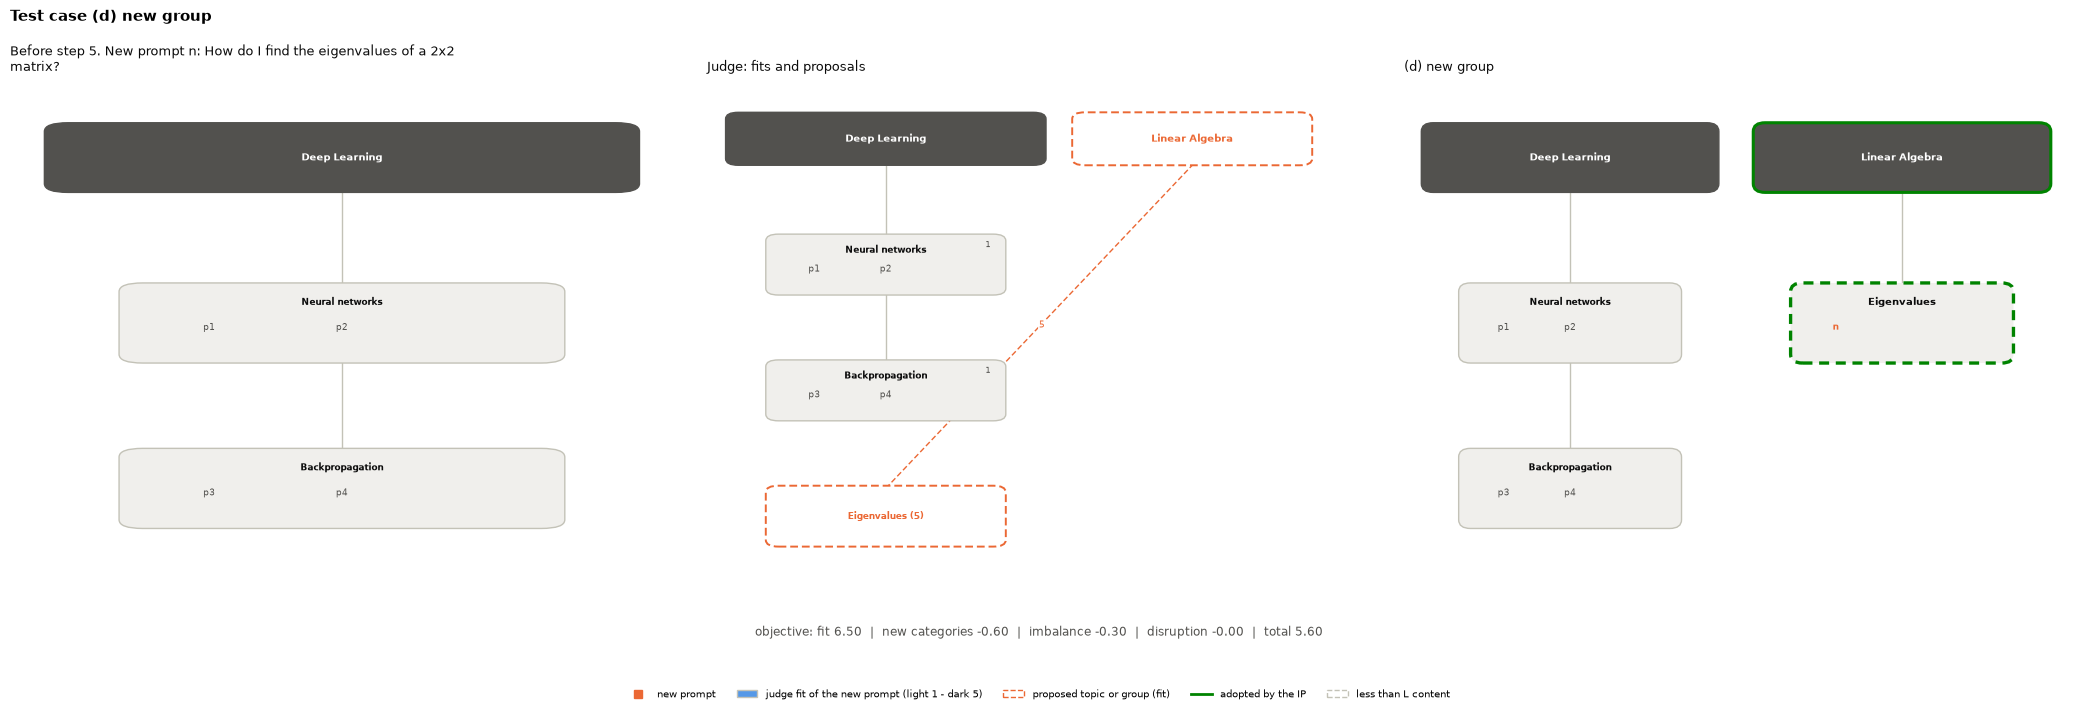

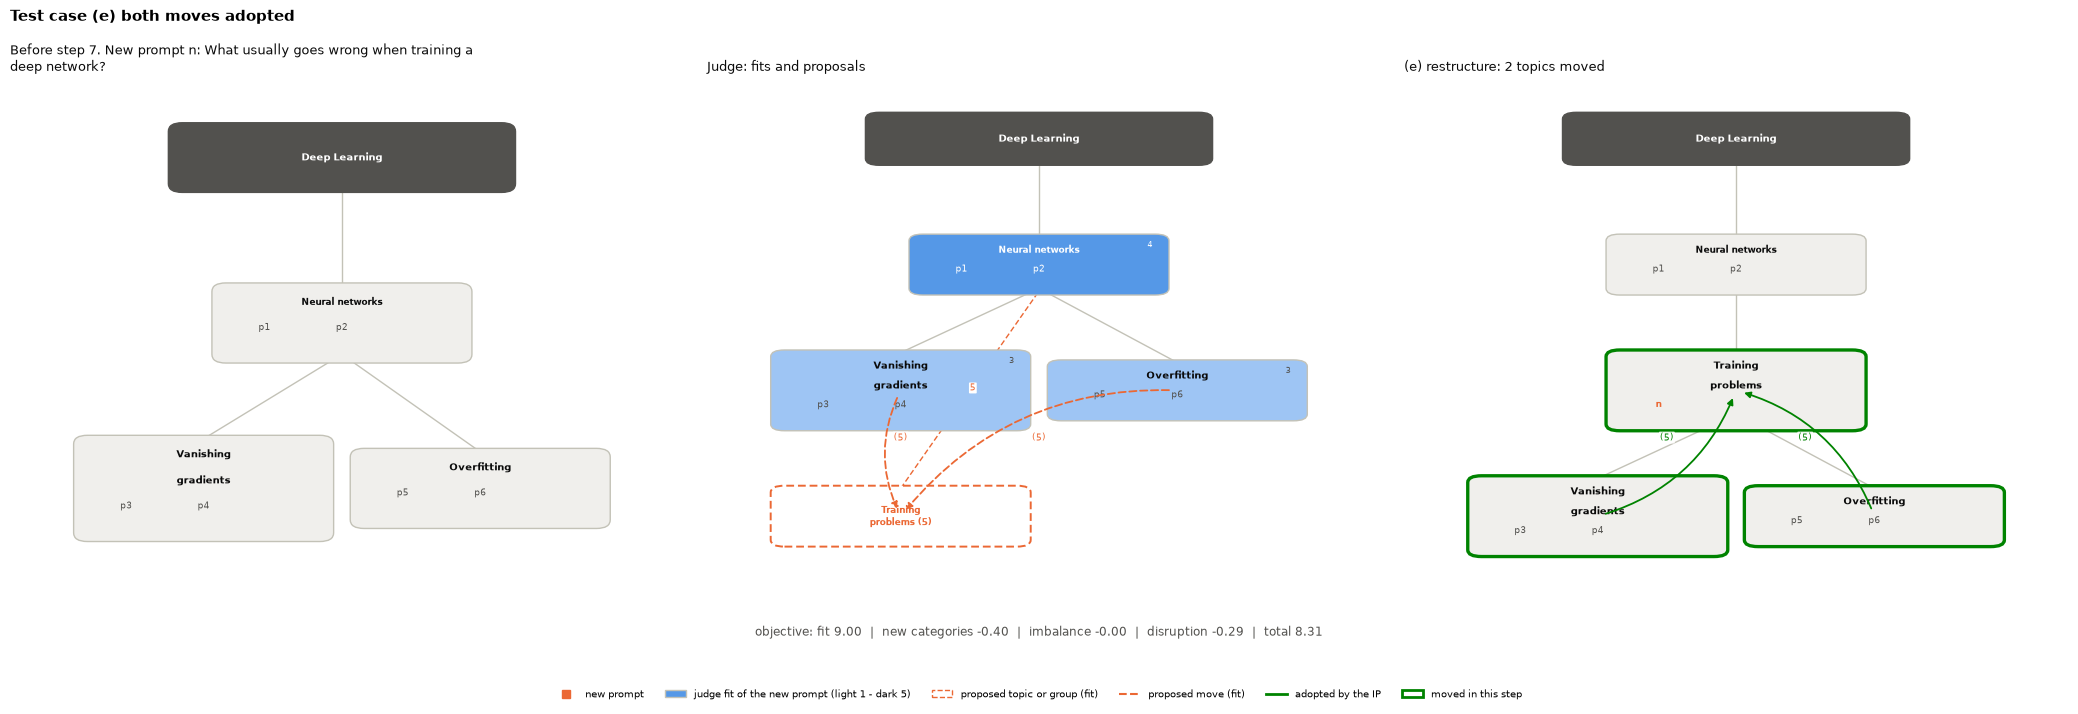

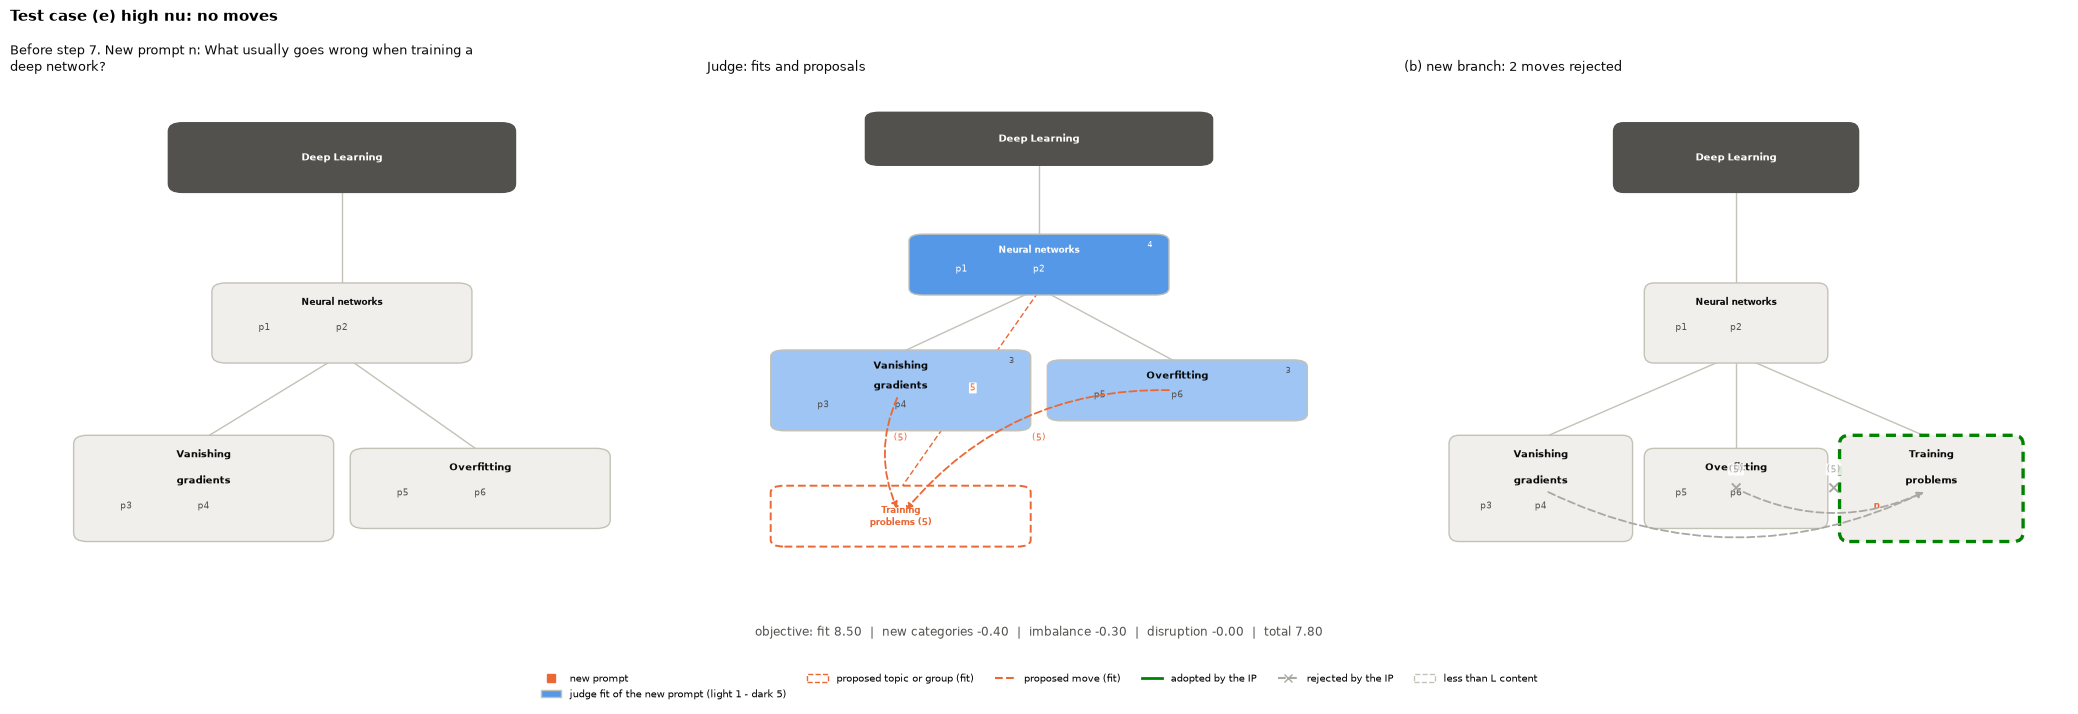

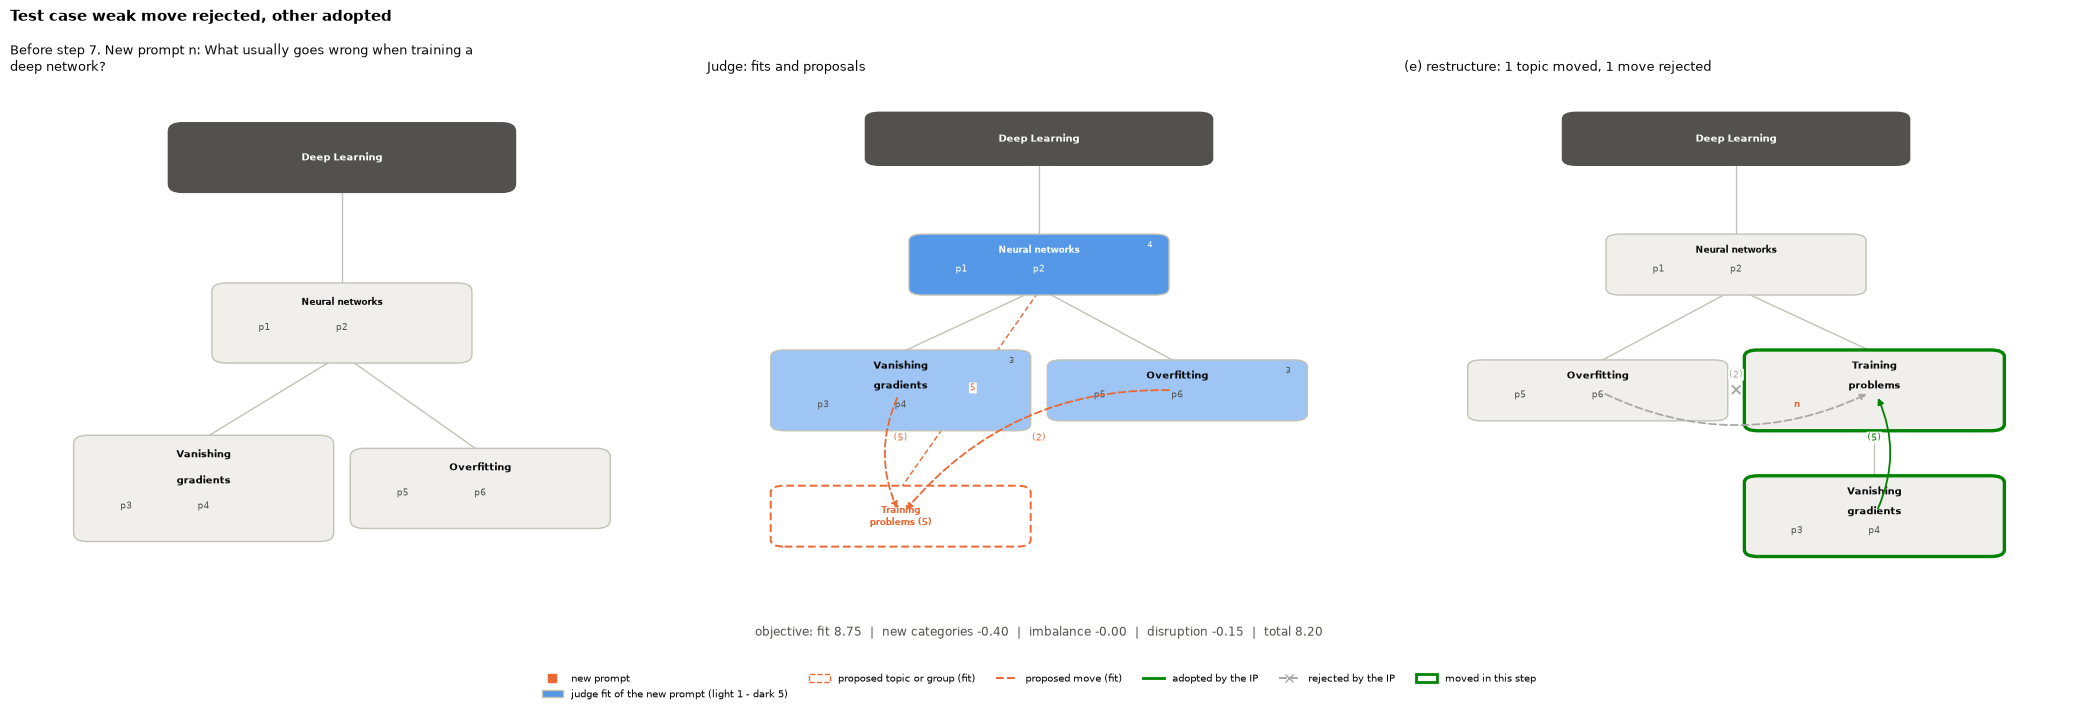

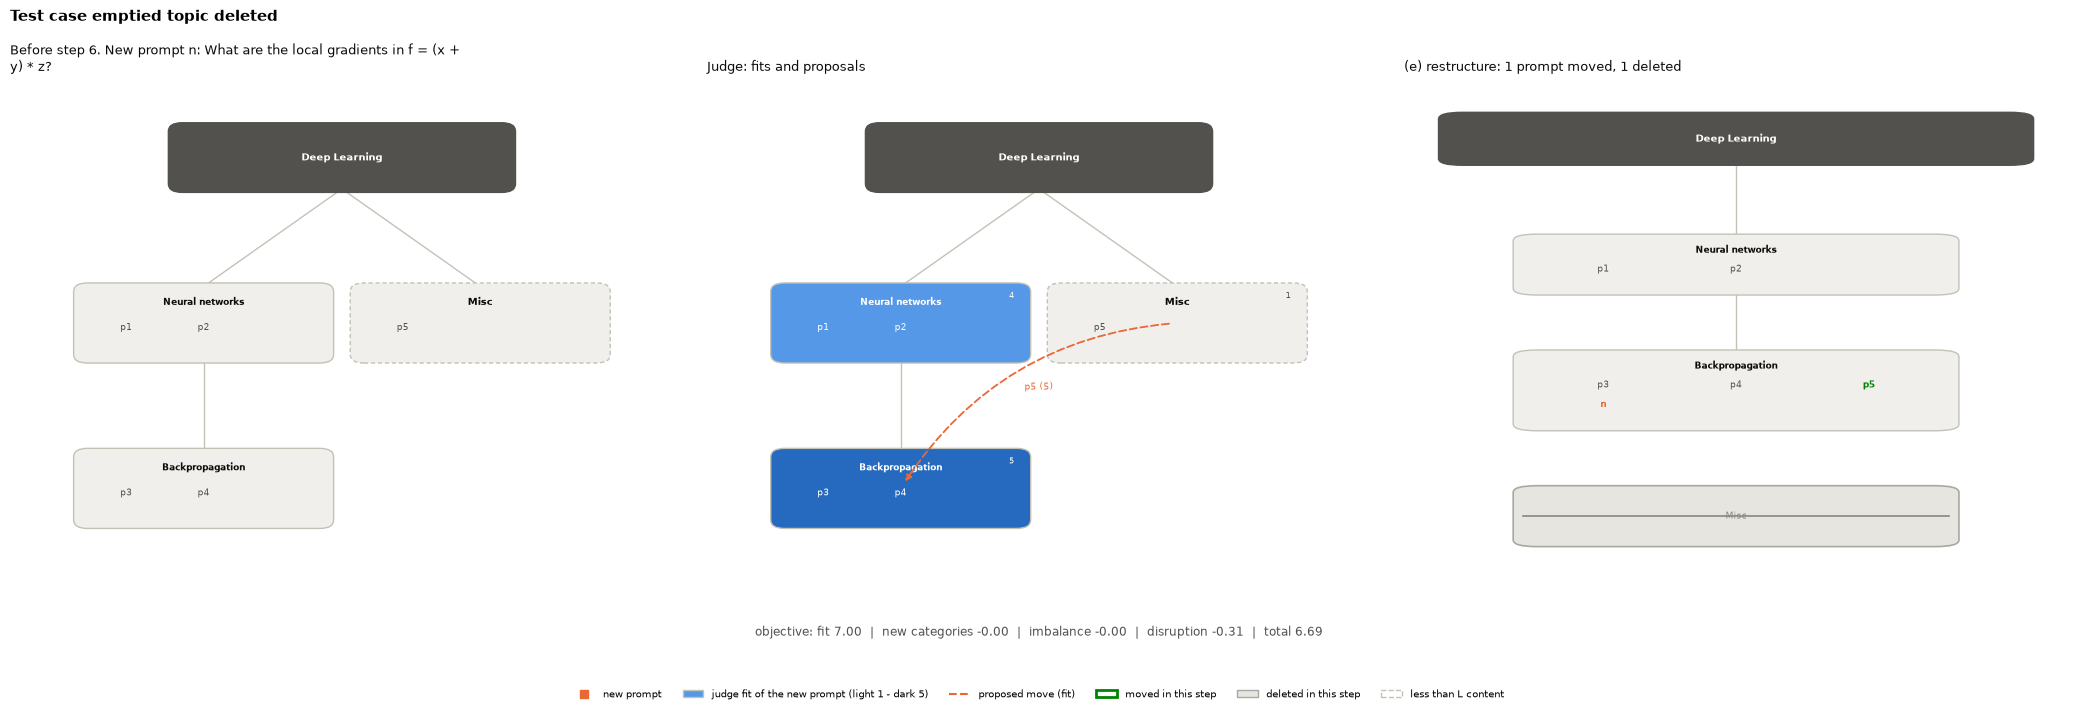

In [6]:
import re
from tests.test_ip import CASES

for name, make in CASES.items():
    case = make()
    after, dec = case.run()
    case.check(after, dec)
    fig = viz.step_view(case.before, case.judge, dec, after, case.params, title=f"Test case {name}")
    fig.savefig(FIG / f"02_case_{re.sub(r'[^a-z0-9]+', '_', name.lower()).strip('_')}.png", dpi=110, bbox_inches="tight")
    plt.show()

In [7]:
res = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests"], cwd=ROOT, capture_output=True, text=True)
print(res.stdout.strip().splitlines()[-1])

11 passed in 0.13s


## Findings

- Walkthrough (oracle judge, step 17, the first restructure): the judge proposes Eigenvalues under
  a new group Linear Algebra, plus three moves. The IP adopts the topic and the group and two prompt
  moves: p21, which had landed in a Deep Learning topic at step 11, goes to Eigenvalues, and p13
  goes to Overfitting. It rejects moving the Overfitting topic under Training problems. Action (e).
- That step's model has 94 variables and 147 constraints and solves in about 1 ms, far below the
  2000 limit of the pip license.
- All eight unit-test cases come out as designed, and the step views show it: add, new branch, new
  tree, new group, both moves adopted, no moves at high `nu`, a weak move rejected while the other
  is adopted, and an emptied topic deleted. The tests also check that `lam_G = 1.0` blocks a new
  group. 11 tests pass.
- The LLM judge step is skipped until a model is chosen (`config.yaml`).